## Part A - Network Construction and Data Processing

Our Project is about an email exchanges in a European research institution. The purpose of selecting this email patterns to show the department structures and who acts as connectors between them. The data come from the [Stanford Network Analysis Project](https://snap.stanford.edu/data/email-Eu-core.html).

- **Node:** one anonymous person.
- **Directed edge:** node `u` sent at least one email to node `v`.
- **Network type:** directed and unweighted.

In [ ]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

In [ ]:
DATA_DIRECTORY = Path(".")
EDGES_FILE = DATA_DIRECTORY / "email-Eu-core.txt.gz"
LABELS_FILE = DATA_DIRECTORY / "email-Eu-core-department-labels.txt.gz"

In [ ]:
edges = pd.read_csv(
    EDGES_FILE,
    sep=r"\s+",
    names=["source", "target"],
    compression="gzip",
)

labels = pd.read_csv(
    LABELS_FILE,
    sep=r"\s+",
    names=["node", "department"],
    compression="gzip",
)

In [ ]:
display(edges.head())
display(labels.head())

,source,target
0,0,1
1,2,3
2,2,4
3,5,6
4,5,7


,node,department
0,0,1
1,1,1
2,2,21
3,3,21
4,4,21


## Data format

Whenever two people email each other, it shows up as a “connection” in our data. We kept it simple: one table shows who emailed whom and another links each person to a department. We know that everyone is anonymous in this dataset because of which we are not looking for individual identities. Instead, we want to see the bigger picture of how people communicate and connect.

In [ ]:
data_checks = pd.Series(
    {
        "Edge rows": len(edges),
        "Duplicate edges": edges.duplicated().sum(),
        "Self-loops": (edges["source"] == edges["target"]).sum(),
        "Missing edge values": edges.isna().sum().sum(),
        "Label rows": len(labels),
        "Duplicate node labels": labels["node"].duplicated().sum(),
        "Missing label values": labels.isna().sum().sum(),
    },
    name="Value",
)

data_checks.to_frame()

,Value
Edge rows,25571
Duplicate edges,0
Self-loops,642
Missing edge values,0
Label rows,1005
Duplicate node labels,0
Missing label values,0


## Data quality and preprocessing

### Checks

- Edge rows: **25,571**.
- Label rows: **1,005**.
- Missing values: **0**.
- Duplicate edges and node labels: **0**.
- Self-loops: **642**.

### Cleaning

Missing data and duplicates have been cleaned up in the pre-processing stage. Emails sent from one individual to themself are considered self-loops and therefore discarded to keep the focus on relationships between individuals. The only edges that were kept are those with a department for each party; all edges with missing data for one or both parties were discarded. Please note that the dataset only indicates whether a relationship exists, not the number of emails that were sent between two people. Therefore, the network that was built represents relationships between people but not the strength of those relationships.

In [ ]:
edges_clean = edges.dropna().drop_duplicates()
edges_clean = edges_clean[edges_clean["source"] != edges_clean["target"]].copy()
labels_clean = labels.dropna().drop_duplicates(subset="node").copy()

valid_nodes = set(labels_clean["node"])
edges_clean = edges_clean[
    edges_clean["source"].isin(valid_nodes)
    & edges_clean["target"].isin(valid_nodes)
].copy()

In [ ]:
graph = nx.from_pandas_edgelist(
    edges_clean,
    source="source",
    target="target",
    create_using=nx.DiGraph,
)

department_by_node = labels_clean.set_index("node")["department"].to_dict()
graph.add_nodes_from(department_by_node)
nx.set_node_attributes(graph, department_by_node, "department")

In [ ]:
network_summary = pd.Series(
    {
        "Nodes": graph.number_of_nodes(),
        "Directed edges": graph.number_of_edges(),
        "Departments": labels_clean["department"].nunique(),
        "Is directed": graph.is_directed(),
        "Density": nx.density(graph),
    },
    name="Value",
)

network_summary.to_frame()

,Value
Nodes,1005
Directed edges,24929
Departments,42
Is directed,True
Density,0.024706


## Constructed network

### Results

- Nodes: **1,005**.
- Directed edges: **24,929**.
- Departments: **42**.
- Density: **0.0247**.

### What this shows

Only about 2.47% of all possible directed connections exist. The network is therefore sparse: direct communication is selective rather than distributed between every possible pair of employees.

### Realistic explanation

It is realistic for a research institution because most employees only need to contact their department and project partners. Low density does not mean poor communication, It shows specialized roles and focused professional relationships.

In [ ]:
largest_departments = (
    labels_clean["department"].value_counts().head(3).index.tolist()
)
selected_nodes = labels_clean.loc[
    labels_clean["department"].isin(largest_departments), "node"
]
subgraph = graph.subgraph(selected_nodes).copy()

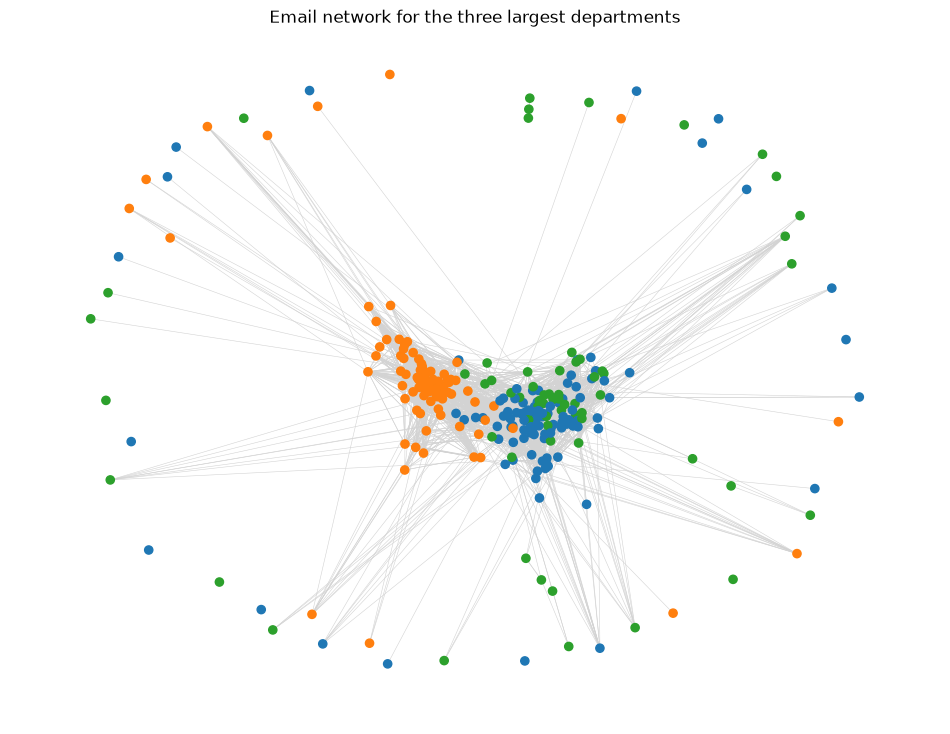

In [ ]:
department_colors = {
    department: color
    for department, color in zip(largest_departments, ["tab:blue", "tab:orange", "tab:green"])
}
node_colors = [
    department_colors[subgraph.nodes[node]["department"]]
    for node in subgraph.nodes
]
positions = nx.spring_layout(subgraph, seed=42)

plt.figure(figsize=(12, 9))
nx.draw_networkx(
    subgraph,
    pos=positions,
    node_color=node_colors,
    node_size=35,
    edge_color="lightgray",
    width=0.4,
    arrows=False,
    with_labels=False,
)
plt.title("Email network for the three largest departments")
plt.axis("off")
plt.show()

## Representative subnetwork

### Results

The figure shows the departments 4, 14, and 1, the three largest departments of the organization. The subnetwork consists of 266 nodes and 3,522 directed edges. The departments are represented by the different colors of the nodes. The arrows are hidden for the sake of visibility.

### What this shows

This figure shows that communication within the department is influenced by the department itself. Also, many connections exist between the different departments. The representation of the network as a spring is only for visibility. Therefore, the distance between nodes does not correspond to the distance between the connected nodes.

### Realistic explanation

Employees in the same department work together in order to complete tasks assigned to them by their supervisors. They may also be involved in teaching activities and research projects of their colleagues in the same department. Therefore, employees in the same department are likely to communicate with each other on a regular basis. Administration, shared services, and other interdepartmental collaborations are likely to connect employees from different departments.

## Short conclusion

After some cleaning up of the data, we arrive at a directed, sparse network of 42 departments. From the visualization we can already make out that communication is influenced by the departments, but this hypothesis needs to be tested in the following sections with the help of community detection and other measures on the network.

# Part B - Network Analysis

This section describes the main structural properties of the email network. It examines node degrees, clustering, connectivity, distances, central nodes and communities.

## Degree distribution

The degree of a node is the number of edges connected to it. In the context of email networks, the in-degree of a node is the number of people who send emails to it, and its out-degree is the number of people who receive emails from it.

In [11]:
in_degrees = pd.Series(dict(graph.in_degree()), name="In-degree")
out_degrees = pd.Series(dict(graph.out_degree()), name="Out-degree")

degree_summary = pd.Series(
    {
        "Average in-degree": in_degrees.mean(),
        "Average out-degree": out_degrees.mean(),
        "Maximum in-degree": in_degrees.max(),
        "Maximum out-degree": out_degrees.max(),
    },
    name="Value",
)

degree_summary.to_frame()

,Value
Average in-degree,24.804975
Average out-degree,24.804975
Maximum in-degree,211.000000
Maximum out-degree,333.000000


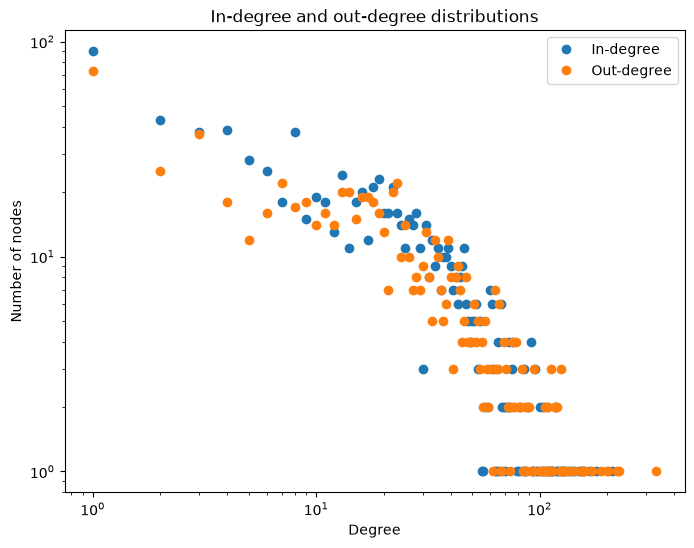

In [12]:
in_degree_counts = in_degrees[in_degrees > 0].value_counts().sort_index()
out_degree_counts = out_degrees[out_degrees > 0].value_counts().sort_index()

plt.figure(figsize=(8, 6))
plt.loglog(in_degree_counts.index, in_degree_counts.values, "o", label="In-degree")
plt.loglog(out_degree_counts.index, out_degree_counts.values, "o", label="Out-degree")
plt.xlabel("Degree")
plt.ylabel("Number of nodes")
plt.title("In-degree and out-degree distributions")
plt.legend()
plt.show()

### Results

- Average in-degree: 24.80.

- Average out-degree: 24.80.

- Maximum in-degree: 211.

- Maximum out-degree: 333.

### What this shows

As we would expect for directed graphs, the average in-degree equals the average out-degree. The maximum degree values are however much higher than the average degree. The log-log plot shows many nodes with low degree and a few nodes with high degree, i.e. a heterogeneous degree distribution.

### Realistic explanation

This can be explained by the fact that different professional roles require different amounts of communication. Most employees work in a small regular group of colleagues, while coordinators, managers, administrative services, technical support as well as interdisciplinary researchers require a broad communication role in order to be successful in their jobs. High degree does not equal high value.

## Clustering, connectivity, and paths

Path length and diameter are not meaningful for the complete directed graph if it is not strongly connected. For this reason, they are calculated on the largest weakly connected component after converting it to an undirected graph.

In [13]:
weak_components = list(nx.weakly_connected_components(graph))
strong_components = list(nx.strongly_connected_components(graph))
largest_weak_nodes = max(weak_components, key=len)
largest_component = graph.subgraph(largest_weak_nodes).to_undirected()

structure_summary = pd.Series(
    {
        "Density": nx.density(graph),
        "Average clustering coefficient": nx.average_clustering(graph),
        "Weakly connected components": len(weak_components),
        "Strongly connected components": len(strong_components),
        "Largest weak component size": largest_component.number_of_nodes(),
        "Average shortest path length": nx.average_shortest_path_length(largest_component),
        "Diameter": nx.diameter(largest_component),
    },
    name="Value",
)

structure_summary.to_frame()

,Value
Density,0.024706
Average clustering coefficient,0.365661
Weakly connected components,20.000000
Strongly connected components,203.000000
Largest weak component size,986.000000
Average shortest path length,2.586934
Diameter,7.000000


### Results

- Directed average clustering: **0.366**.
- Weakly connected components: **20**.
- Strongly connected components: **203**.
- Largest weak component: **986 of 1,005 nodes**.
- Undirected average path length in this component: **2.59**.
- Undirected diameter: **7**.

### What this shows

The clustering in the directed network is high compared to the directed density of 0.0247. The majority of nodes are part of a single weak component. In this component the undirected average path length is 2.59. The undirected diameter is 7. These numbers indicate that the network has potential connectivity after the direction of the links is removed.

### Realistic explanation

These local groups could be labs, departments, administration teams, projects in common etc. colleagues in these teams have many contacts in common. Transversal roles such as central administration, technical services, management, project coordination, etc. can create short paths.

## Centrality measures

Three measures are used to identify important nodes:

- **In-degree centrality:** nodes receiving connections from many people.
- **Out-degree centrality:** nodes sending connections to many people.
- **Betweenness centrality:** nodes that often connect different parts of the network.

In [14]:
centrality_measures = {
    "In-degree": nx.in_degree_centrality(graph),
    "Out-degree": nx.out_degree_centrality(graph),
    "Betweenness": nx.betweenness_centrality(graph, k=100, seed=42),
}

top_centrality_rows = []
for measure, values in centrality_measures.items():
    for node, score in sorted(values.items(), key=lambda item: item[1], reverse=True)[:5]:
        top_centrality_rows.append(
            {"Measure": measure, "Node": node, "Score": score}
        )

top_centrality = pd.DataFrame(top_centrality_rows)
top_centrality

,Measure,Node,Score
0,In-degree,160,0.210159
1,In-degree,62,0.177291
2,In-degree,107,0.167331
3,In-degree,121,0.155378
4,In-degree,86,0.152390
5,Out-degree,160,0.331673
6,Out-degree,82,0.225100
7,Out-degree,121,0.220120
8,Out-degree,107,0.202191
9,Out-degree,86,0.200199


### Results

The above table lists the first five nodes for in-degree, out-degree and estimated betweenness. Node 160 is first for in-degree, out-degree and estimated betweenness. Other nodes are first for only some of the other measures.

### What this shows

This means that Node 160 is a major sender, receiver and intermediary in the communication structure. Other than Node 160, the rankings for receiving, sending and connecting groups are different, which shows that these are different roles within the communication structure. Since betweenness is estimated for 100 nodes, the results for betweenness would change for another sample of 100 nodes.

### Realistic explanation

The highly ranked node may play a role throughout the entire institution. Other highly ranked nodes may play more specialized roles, such as sending information or receiving requests for information. Because we do not know the identities of the nodes, we cannot confirm these roles. Also, centrality does not necessarily correspond to professional or personal importance.

## Community detection

Louvain community detection is applied to the undirected version of the network because the method groups nodes with many internal connections. Modularity measures how clearly these groups are separated.

In [15]:
undirected_graph = graph.to_undirected()
communities = nx.community.louvain_communities(undirected_graph, seed=42)
community_sizes = sorted([len(community) for community in communities], reverse=True)
community_modularity = nx.community.modularity(undirected_graph, communities)
department_assortativity = nx.attribute_assortativity_coefficient(
    undirected_graph, "department"
)
internal_edges = sum(
    department_by_node[source] == department_by_node[target]
    for source, target in undirected_graph.edges()
)
internal_edge_share = internal_edges / undirected_graph.number_of_edges()

community_summary = pd.Series(
    {
        "Detected communities": len(communities),
        "Modularity": community_modularity,
        "Largest community": max(community_sizes),
        "Smallest community": min(community_sizes),
        "Department assortativity": department_assortativity,
        "Within-department edges (%)": 100 * internal_edge_share,
        "Between-department edges (%)": 100 * (1 - internal_edge_share),
    },
    name="Value",
)

community_summary.to_frame()

,Value
Detected communities,27.000000
Modularity,0.416418
Largest community,248.000000
Smallest community,1.000000
Department assortativity,0.302442
Within-department edges (%),33.571962
Between-department edges (%),66.428038


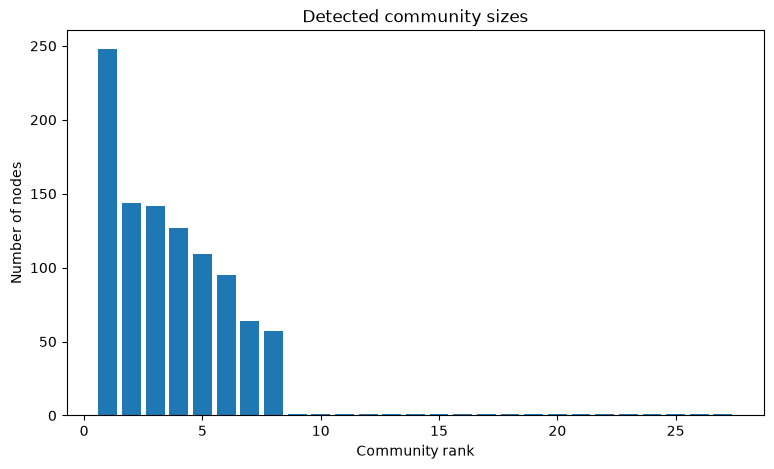

In [16]:
plt.figure(figsize=(9, 5))
plt.bar(range(1, len(community_sizes) + 1), community_sizes)
plt.xlabel("Community rank")
plt.ylabel("Number of nodes")
plt.title("Detected community sizes")
plt.show()

,Value
Normalized mutual information,0.590263
Community purity,0.463682


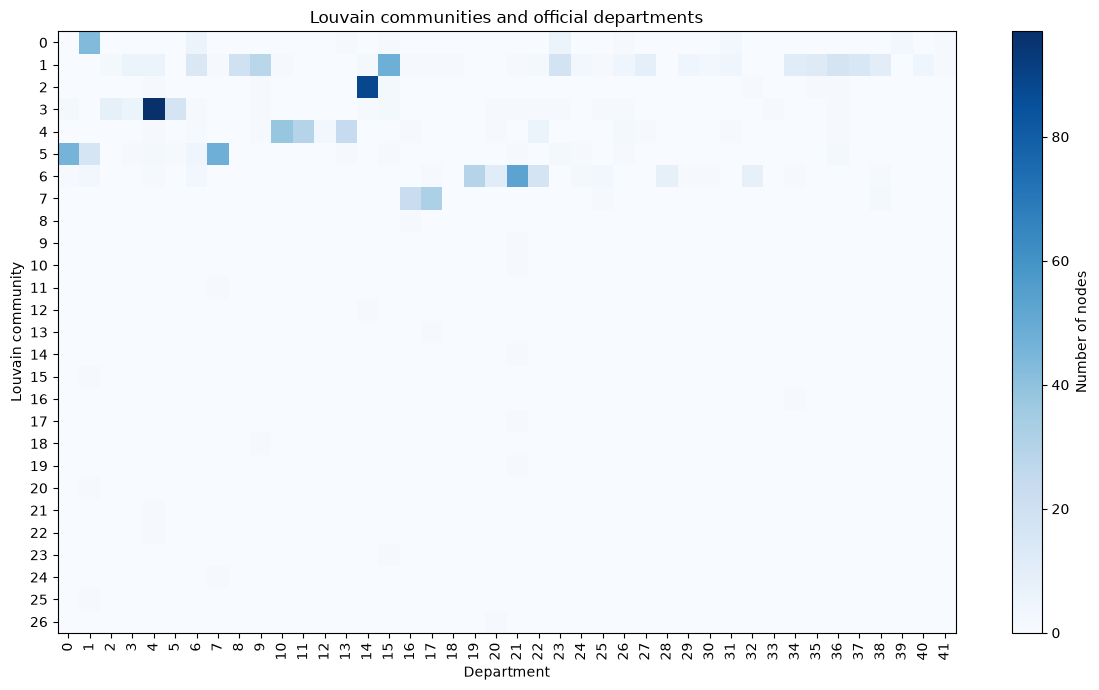

In [17]:
community_by_node = {
    node: community_id
    for community_id, community in enumerate(communities)
    for node in community
}
community_department = pd.crosstab(
    pd.Series(community_by_node, name="Community"),
    pd.Series(department_by_node, name="Department"),
)

total_nodes = community_department.to_numpy().sum()
joint = community_department / total_nodes
community_probabilities = joint.sum(axis=1)
department_probabilities = joint.sum(axis=0)
mutual_information = sum(
    probability * math.log(
        probability / (community_probabilities[community] * department_probabilities[department])
    )
    for community in joint.index
    for department in joint.columns
    if (probability := joint.loc[community, department]) > 0
)
community_entropy = -sum(p * math.log(p) for p in community_probabilities if p > 0)
department_entropy = -sum(p * math.log(p) for p in department_probabilities if p > 0)
normalized_mutual_information = 2 * mutual_information / (community_entropy + department_entropy)
community_purity = community_department.max(axis=1).sum() / total_nodes

display(pd.Series({
    "Normalized mutual information": normalized_mutual_information,
    "Community purity": community_purity,
}, name="Value").to_frame())

plt.figure(figsize=(12, 7))
plt.imshow(community_department, aspect="auto", cmap="Blues")
plt.colorbar(label="Number of nodes")
plt.xlabel("Department")
plt.ylabel("Louvain community")
plt.title("Louvain communities and official departments")
plt.xticks(range(len(community_department.columns)), community_department.columns, rotation=90)
plt.yticks(range(len(community_department.index)), community_department.index)
plt.tight_layout()
plt.show()

### Results

- Louvain communities: 27 (compared to 42 departments).

- Community sizes: 1 to 248 nodes.

- Modularity: 0.416.

- Department assortativity: 0.302.

- Within-department edges: 33.57%.

- Between-department edges: 66.43%.

- Normalized mutual information: 0.590.

- Community purity: 0.464.

### What this shows

The assortativity and NMI values are positive, showing that communication communities and departments are related to each other but are not identical. Most of the communication network’s edges connect departments. The average purity of communication communities is low (0.464), i.e. they are composed of many different departments. The modularity is positive (0.416), i.e. communication is organized by links, but the organization is not that of departments.

### Realistic explanation

The department is the base of most of the interactions within the company, but there are also many other activities, such as research projects, teaching, administrative tasks, shared equipment, etc., and collaborations with members of other departments.

## Short conclusion

The network is sparse with local clustering. The undirected version of the largest weakly connected component has short paths but the directed version does not. There are nodes with higher degree than average and better connected than average. Department assortativity and within-department edges describe how communication reflects official organization structure. Communities found by link-based partitioning of the network (Louvain) do not necessarily correspond to departments.

# Part C - Theoretical Models and Network Properties
We compare the empirical network to two theoretical models: the Erdős–Rényi random model and the Barabási–Albert preferential attachment model. We analyze both models with respect to their small-world and scale-free properties. To compare the empirical network to both models, we first transform the empirical graph into an undirected graph, because both models are only defined for undirected networks.
The two models described above are suitable for the analysis of the email dataset because the network is sparse and shows a high clustering. The Erdős–Rényi random model can be used as a random baseline in order to verify whether the observed organization can be explained by chance. The degree analysis revealed that there are a small number of very highly connected employees in the network. The Barabási–Albert model can be used in order to verify whether the observed organization can be explained by preferential attachment and the appearance of hubs in the network with a long-tailed degree distribution. Moreover, we are most familiar with these two models and thus can apply them in the most accurate way and discuss them in the most comprehensive way.

## Model construction

The Erdős–Rényi model adds edges uniformly and independently. It has the same number of nodes and edges as the corresponding empirical undirected graph. The Barabási–Albert model grows by preferential attachment, i.e. new nodes are added to the network and are preferentially connected to existing nodes with higher degree. The attachment parameter is set such that the number of edges in the network is similar to that of the Erdős–Rényi model.

In [18]:
empirical_graph = graph.to_undirected()
number_of_nodes = empirical_graph.number_of_nodes()
number_of_edges = empirical_graph.number_of_edges()

random_graph = nx.gnm_random_graph(
    number_of_nodes, number_of_edges, seed=42
)

ba_links_per_node = round(number_of_edges / number_of_nodes)
preferential_graph = nx.barabasi_albert_graph(
    number_of_nodes, ba_links_per_node, seed=42
)
model_trials = 10

pd.Series(
    {
        "Empirical nodes": number_of_nodes,
        "Empirical edges": number_of_edges,
        "BA links per new node": ba_links_per_node,
    },
    name="Value",
).to_frame()

,Value
Empirical nodes,1005
Empirical edges,16064
BA links per new node,16


## Erdős–Rényi model and small-world properties

A small-world network combines short paths with much stronger clustering than a comparable random graph. The measurements below use the largest connected component of each network so that path length is well defined.

In [19]:
def calculate_model_metrics(network):
    largest_nodes = max(nx.connected_components(network), key=len)
    largest_network = network.subgraph(largest_nodes)
    return {
        "Nodes": network.number_of_nodes(),
        "Edges": network.number_of_edges(),
        "Average degree": sum(dict(network.degree()).values()) / network.number_of_nodes(),
        "Clustering": nx.average_clustering(network),
        "Average path length": nx.average_shortest_path_length(largest_network),
    }

model_rows = [
    {"Model": "Empirical", "Trial": 0, **calculate_model_metrics(empirical_graph)}
]
for trial in range(model_trials):
    models = {
        "Erdos-Renyi": nx.gnm_random_graph(number_of_nodes, number_of_edges, seed=42 + trial),
        "Barabasi-Albert": nx.barabasi_albert_graph(number_of_nodes, ba_links_per_node, seed=42 + trial),
    }
    for name, network in models.items():
        model_rows.append({"Model": name, "Trial": trial, **calculate_model_metrics(network)})

model_results = pd.DataFrame(model_rows)
model_comparison = model_results.groupby("Model").mean(numeric_only=True).drop(columns="Trial")

model_comparison

,Nodes,Edges,Average degree,Clustering,Average path length
Model,,,,,
Barabasi-Albert,1005.0,15824.0,31.490547,0.080673,2.294599
Empirical,1005.0,16064.0,31.968159,0.399355,2.586934
Erdos-Renyi,1005.0,16064.0,31.968159,0.031854,2.317902


In [20]:
small_world_ratio = (
    model_comparison.loc["Empirical", "Clustering"]
    / model_comparison.loc["Erdos-Renyi", "Clustering"]
) / (
    model_comparison.loc["Empirical", "Average path length"]
    / model_comparison.loc["Erdos-Renyi", "Average path length"]
)

model_variability = model_results.groupby("Model").std(numeric_only=True).drop(columns="Trial")
display(pd.Series({"Small-world ratio": small_world_ratio}, name="Value").to_frame())
model_variability.loc[["Erdos-Renyi", "Barabasi-Albert"]]

,Value
Small-world ratio,11.23325


,Nodes,Edges,Average degree,Clustering,Average path length
Model,,,,,
Erdos-Renyi,0.0,0.0,0.0,0.000247,0.000628
Barabasi-Albert,0.0,0.0,0.0,0.001184,0.002947


### Results

- Empirical clustering: **0.399**.
- Mean Erdős–Rényi clustering across 10 graphs: about **0.032**.
- Empirical average path length: **2.59**.
- Mean Erdős–Rényi path length: about **2.32**.
- Small-world ratio: **11.23**.

### What this shows

The empirical network has more local clustering than a similar Erdős–Rényi graph, while having almost the same path length. Therefore, the ratio above 1 supports the small-world hypothesis. Several random seeds were used to avoid comparing the empirical network with only one Erdős–Rényi graph.

### Realistic explanation

The university-like institution consists of many dense local working groups (departments, labs, projects) and a few transversal connections (administration, services, managers, interdisciplinary projects). These provide short cuts between the clusters.

## Barabási–Albert model and scale-free properties

A scale-free network has an approximately power-law degree distribution over part of its range. The complementary cumulative degree distribution is shown on log-log axes to compare the empirical data with random connection and preferential attachment.

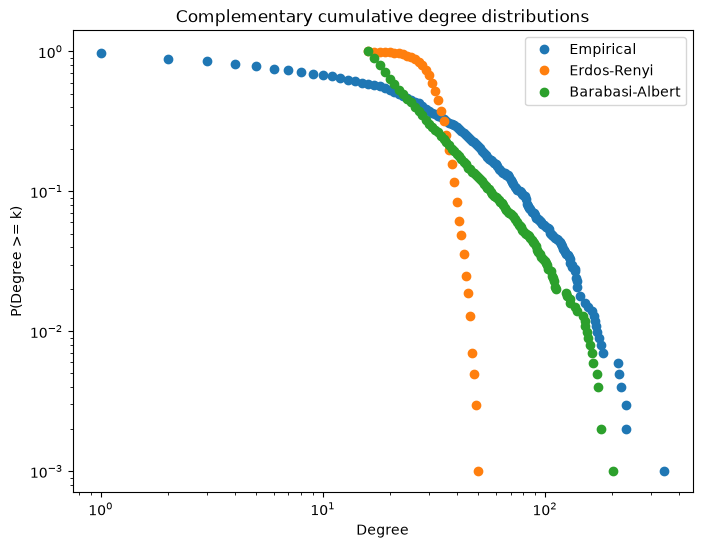

In [21]:
def degree_ccdf(network):
    degrees = pd.Series(dict(network.degree()))
    degree_values = sorted(degrees.unique())
    probabilities = [(degrees >= degree).mean() for degree in degree_values]
    return degree_values, probabilities

plt.figure(figsize=(8, 6))
for name, network in {
    "Empirical": empirical_graph,
    "Erdos-Renyi": random_graph,
    "Barabasi-Albert": preferential_graph,
}.items():
    degrees, probabilities = degree_ccdf(network)
    plt.loglog(degrees, probabilities, marker="o", linestyle="none", label=name)

plt.xlabel("Degree")
plt.ylabel("P(Degree >= k)")
plt.title("Complementary cumulative degree distributions")
plt.legend()
plt.show()

In [22]:
degree_model_summary = pd.DataFrame(
    {
        name: {
            "Maximum degree": max(dict(network.degree()).values()),
            "Degree standard deviation": pd.Series(dict(network.degree())).std(),
        }
        for name, network in {
            "Empirical": empirical_graph,
            "Erdos-Renyi": random_graph,
            "Barabasi-Albert": preferential_graph,
        }.items()
    }
).T

degree_model_summary

,Maximum degree,Degree standard deviation
Empirical,345.0,36.959747
Erdos-Renyi,50.0,5.559080
Barabasi-Albert,202.0,24.756285


### Results

- Maximum degree: empirical 345, Erdős–Rényi 50, Barabási–Albert 202.

- Degree standard deviation: empirical 36.96, Erdős–Rényi 5.56, Barabási–Albert 24.76.

### What this shows

The empirical network is much more heterogeneous than the random graph and contains larger hubs. Although the Barabási–Albert graph reproduces some of the network’s heterogeneity, it fails to match the distribution of the empirical network. The network is heavy-tailed, but this visual comparison is not sufficient to establish the exact distribution of degrees and whether or not the network is generated by preferential attachment.

### Realistic explanation

Preferential attachment of already known points of contact (employees) to new ones is only one of many ways that a hub can form in a network. For example, institutional hierarchy, size of departments, central services and responsibilities of employees are all other ways that a hub can form in a network.

## Assumptions and limitations

- both models ignore the edges direction and the department label.

- Erdős–Rényi: Independent links with same connection probability.

- preferential attachment model (Barabási–Albert) used to generate networks with some degree heterogeneity.

- The empirical data do not contain any timestamps and therefore growth of the network cannot be tested.

- The number of edges in the Barabási–Albert graph is similar to the number of edges in the empirical network, but not exactly the same, as the parameter m can only be an integer.

- A formal statistical power-law test would be needed to confirm a scale-free distribution.

## Short conclusion

The empirical network has high clustering and short path lengths as well as a heterogeneous degree distribution. This network can be interpreted as a small-world network. The preferential attachment model can be used to generate networks with some degree heterogeneity. However, these models do not account for departments, professional roles and organizational restrictions. Thus, the real network is likely the result of a variety of different mechanisms.

# Part D - Role of Bridge Employees and Network Robustness

The focused research question is: **How important are bridge employees for maintaining communication between departments?**

The research question for this part of the project follows on from the previous parts, in particular from Part B where we identified short paths, heterogeneous degree distribution, central nodes and communities and Part C where we compared the empirical properties of the network of the organization with those of random and preferential attachment models. The results from Part C supported the small-world nature of the network but also showed that the network did not correspond to either of the two models of network development. Thus we are interested to know whether the interdepartmental communication in the organization depends on a small number of specific employees.

## Definition of a bridge employee

The bridge score of a node is equal to the number of interdepartmental neighbors of that node. Here, the graph under consideration is an undirected graph, as the study focuses on the availability of communication connections, regardless of whether they were originally directed or not.

In [23]:
robustness_graph = graph.to_undirected()

bridge_scores = {
    node: sum(
        robustness_graph.nodes[neighbor]["department"]
        != robustness_graph.nodes[node]["department"]
        for neighbor in robustness_graph.neighbors(node)
    )
    for node in robustness_graph.nodes
}
degree_scores = dict(robustness_graph.degree())
external_shares = {
    node: bridge_scores[node] / degree_scores[node] if degree_scores[node] else 0
    for node in robustness_graph.nodes
}
departments_reached = {
    node: len({department_by_node[neighbor] for neighbor in robustness_graph.neighbors(node)})
    for node in robustness_graph.nodes
}

In [24]:
top_bridge_nodes = sorted(
    bridge_scores, key=lambda node: (bridge_scores[node], node), reverse=True
)[:10]

top_bridges = pd.DataFrame(
    {
        "Node": top_bridge_nodes,
        "Department": [department_by_node[node] for node in top_bridge_nodes],
        "Degree": [degree_scores[node] for node in top_bridge_nodes],
        "Interdepartmental neighbors": [bridge_scores[node] for node in top_bridge_nodes],
        "External connection share": [
            external_shares[node] for node in top_bridge_nodes
        ],
        "Departments reached": [departments_reached[node] for node in top_bridge_nodes],
    }
)

department_bridge_summary = pd.DataFrame({
    "Department size": labels_clean["department"].value_counts(),
    "Top bridges": top_bridges["Department"].value_counts(),
}).fillna(0).astype(int)
department_bridge_summary["Top bridges per 100 employees"] = (
    100 * department_bridge_summary["Top bridges"]
    / department_bridge_summary["Department size"]
)

display(top_bridges)
department_bridge_summary.sort_values("Top bridges", ascending=False).head()

,Node,Department,Degree,Interdepartmental neighbors,External connection share,Departments reached
0,160,36,345,334,0.968116,36
1,121,36,232,215,0.926724,39
2,82,36,231,212,0.917749,38
3,107,36,219,204,0.931507,37
4,62,36,214,204,0.953271,36
5,86,36,216,202,0.935185,31
6,434,34,183,175,0.956284,36
7,13,26,178,173,0.971910,34
8,5,25,169,164,0.970414,36
9,64,25,168,163,0.970238,32


,Department size,Top bridges,Top bridges per 100 employees
36,22,6,27.272727
25,6,2,33.333333
34,13,1,7.692308
26,9,1,11.111111
4,109,0,0.000000


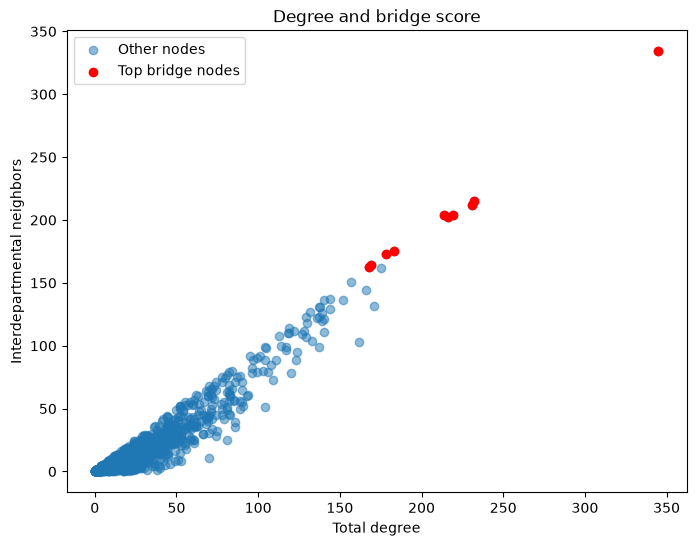

In [25]:
plt.figure(figsize=(8, 6))
plt.scatter(
    [degree_scores[node] for node in robustness_graph.nodes],
    [bridge_scores[node] for node in robustness_graph.nodes],
    alpha=0.5,
    label="Other nodes",
)
plt.scatter(
    [degree_scores[node] for node in top_bridge_nodes],
    [bridge_scores[node] for node in top_bridge_nodes],
    color="red",
    label="Top bridge nodes",
)
plt.xlabel("Total degree")
plt.ylabel("Interdepartmental neighbors")
plt.title("Degree and bridge score")
plt.legend()
plt.show()

### Results

- Node 160 has the highest bridge score (334 interdepartmental neighbors / 345 total neighbors).

- The top ten bridge scores have external connection shares greater than 91%.

- Six of the top ten nodes are from department 36.

### What this shows

While Department 36 only has 22 employees, six of the ten highest bridge scores are found there. External connection shares greater than 91% for the top ten bridge scores are highly correlated with degree, as the bridge score counts external neighbors. While external share and the number of departments reached add useful information, the external share alone can overvalue a node with few contacts.

### Realistic explanation

The nodes in the above graph could be administration, coordination, technical support, management or project management for several departments. These roles naturally create external connections. However, the department names and the employees are anonymous so these are only hypotheses and not the actual job functions of the above nodes.

## Random and targeted attacks

The experiment removes **0%, 1%, 2%, 5%, and 10%** of the original nodes. Five strategies are clearly separated:

- **Random attack:** nodes are selected without using network information. Results are averaged over 20 trials.
- **Targeted total-degree attack:** nodes with the most overall contacts are removed first.
- **Targeted in-degree attack:** nodes receiving connections from the most people are removed first.
- **Targeted out-degree attack:** nodes sending connections to the most people are removed first.
- **Targeted bridge attack:** nodes with the highest bridge score are removed first.

Random attacks provide a baseline, while targeted attacks represent deliberate removal using structural information. After each attack, the analysis measures the largest connected component, the number of components and the proportion of interdepartmental edges that remain.

In [26]:
import random

removal_percentages = [0, 1, 2, 5, 10]
random_trials = 20
original_node_count = robustness_graph.number_of_nodes()
original_cross_edges = sum(
    department_by_node[source] != department_by_node[target]
    for source, target in robustness_graph.edges()
)

attack_scores = {
    "Targeted total-degree attack": degree_scores,
    "Targeted in-degree attack": dict(graph.in_degree()),
    "Targeted out-degree attack": dict(graph.out_degree()),
    "Targeted bridge attack": bridge_scores,
}
attack_orders = {
    strategy: sorted(
        scores, key=lambda node: (scores[node], node), reverse=True
    )
    for strategy, scores in attack_scores.items()
}

## Overlap between targeted rankings

The similar attack curves may result from the strategies selecting many of the same employees. The table compares the top 10% of nodes in each targeted ranking. A value of 100% means that two rankings select exactly the same nodes.

In [27]:
ranking_labels = {
    "Total degree": "Targeted total-degree attack",
    "In-degree": "Targeted in-degree attack",
    "Out-degree": "Targeted out-degree attack",
    "Bridge score": "Targeted bridge attack",
}
top_count = round(original_node_count * 0.10)
top_rankings = {
    label: set(attack_orders[strategy][:top_count])
    for label, strategy in ranking_labels.items()
}
overlap_matrix = pd.DataFrame(
    [
        [100 * len(top_rankings[row] & top_rankings[column]) / top_count for column in top_rankings]
        for row in top_rankings
    ],
    index=top_rankings,
    columns=top_rankings,
).round(1)

overlap_matrix

,Total degree,In-degree,Out-degree,Bridge score
Total degree,100.0,85.0,92.0,84.0
In-degree,85.0,100.0,79.0,79.0
Out-degree,92.0,79.0,100.0,81.0
Bridge score,84.0,79.0,81.0,100.0


### Results

- Overall overlap range: **79% to 92%**.
- Total degree and out-degree: **92%**.
- Total degree and in-degree: **85%**.
- Total degree and bridge score: **84%**.
- Lowest observed overlap: **79%**.

### What this shows

Strategies used to determine the central group are fairly similar. The degree of overlap between total degree and out-degree is 92%. Thus the two strategies result in almost identical attack curves. Bridge targeting slightly removes more external edges than total degree and in-degree targeting slightly causes less fragmentation than total degree.

### Realistic explanation

It is possible for an employee to actively contact many people and receive many responses, thus acting as a sender, receiver, hub and bridge across departments in an institution. Therefore, coordination and service roles can be viewed in the same way as being a sender, receiver, hub and bridge.

In [28]:
def calculate_attack_metrics(nodes_to_remove):
    attacked_graph = robustness_graph.copy()
    attacked_graph.remove_nodes_from(nodes_to_remove)
    components = list(nx.connected_components(attacked_graph))
    largest_component_size = max(map(len, components), default=0)
    remaining_cross_edges = sum(
        department_by_node[source] != department_by_node[target]
        for source, target in attacked_graph.edges()
    )
    return {
        "Largest component (%)": 100 * largest_component_size / original_node_count,
        "Largest component among remaining nodes (%)": (
            100 * largest_component_size / attacked_graph.number_of_nodes()
            if attacked_graph.number_of_nodes() else 0
        ),
        "Number of components": len(components),
        "Interdepartmental edges (%)": 100 * remaining_cross_edges / original_cross_edges,
    }

attack_rows = []
all_nodes = list(robustness_graph.nodes())

for percentage in removal_percentages:
    removal_count = round(original_node_count * percentage / 100)

    for strategy, order in attack_orders.items():
        metrics = calculate_attack_metrics(order[:removal_count])
        attack_rows.append(
            {"Strategy": strategy, "Removed (%)": percentage, **metrics}
        )

    for trial in range(random_trials):
        generator = random.Random(42 + trial)
        removed_nodes = generator.sample(all_nodes, removal_count)
        metrics = calculate_attack_metrics(removed_nodes)
        attack_rows.append(
            {"Strategy": "Random attack", "Removed (%)": percentage, **metrics}
        )

attack_results = pd.DataFrame(attack_rows)

In [29]:
attack_summary = (
    attack_results.groupby(["Strategy", "Removed (%)"], as_index=False)
    .agg(
        {
            "Largest component (%)": "mean",
            "Largest component among remaining nodes (%)": "mean",
            "Number of components": "mean",
            "Interdepartmental edges (%)": "mean",
        }
    )
)

attack_summary

,Strategy,Removed (%),Largest component (%),Largest component among remaining nodes (%),Number of components,Interdepartmental edges (%)
0,Random attack,0,98.109453,98.109453,20.00,100.000000
1,Random attack,1,97.059701,98.035176,20.55,97.940680
2,Random attack,2,96.064677,98.015228,20.55,96.190610
3,Random attack,5,92.731343,97.586387,24.05,91.001312
4,Random attack,10,87.497512,97.165746,26.65,81.138600
5,Targeted bridge attack,0,98.109453,98.109453,20.00,100.000000
6,Targeted bridge attack,1,96.218905,97.185930,29.00,80.901509
7,Targeted bridge attack,2,94.726368,96.649746,34.00,68.859526
8,Targeted bridge attack,5,89.950249,94.659686,52.00,43.838441
9,Targeted bridge attack,10,83.084577,92.265193,71.00,25.133539


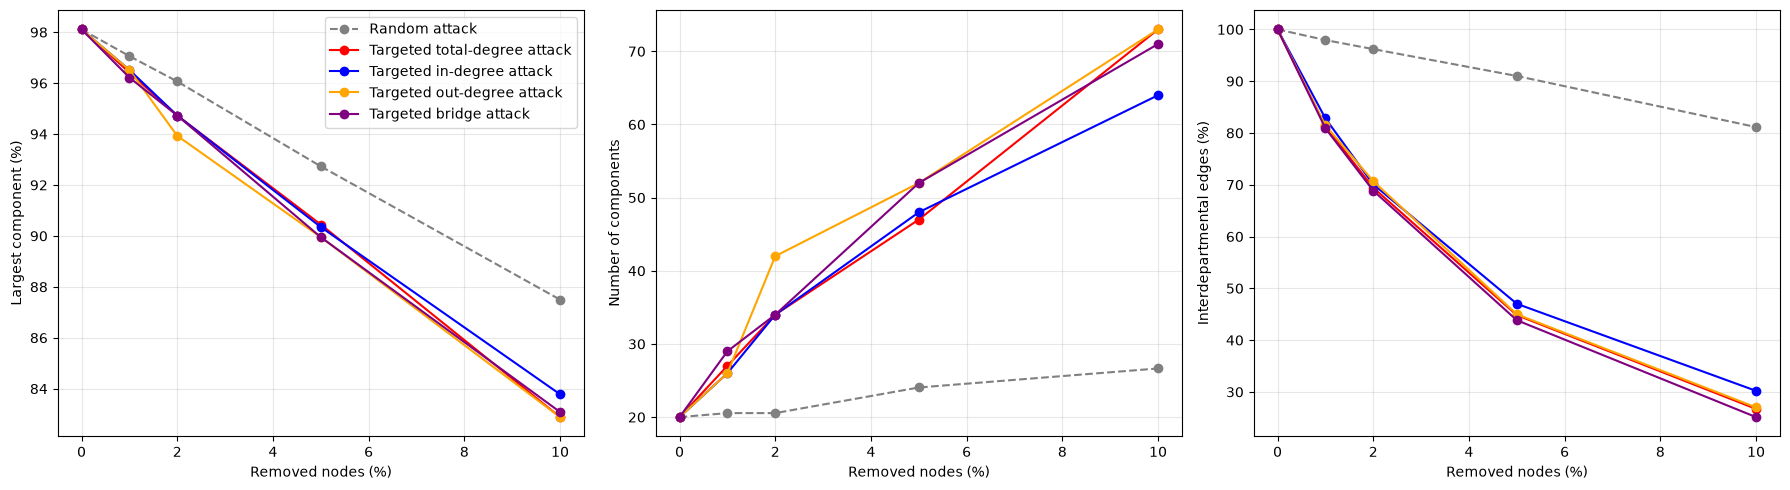

In [30]:
styles = {
    "Random attack": {"color": "gray", "linestyle": "--"},
    "Targeted total-degree attack": {"color": "red", "linestyle": "-"},
    "Targeted in-degree attack": {"color": "blue", "linestyle": "-"},
    "Targeted out-degree attack": {"color": "orange", "linestyle": "-"},
    "Targeted bridge attack": {"color": "purple", "linestyle": "-"},
}
metrics = [
    "Largest component (%)",
    "Number of components",
    "Interdepartmental edges (%)",
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, metric in zip(axes, metrics):
    for strategy, style in styles.items():
        values = attack_summary[attack_summary["Strategy"] == strategy]
        axis.plot(
            values["Removed (%)"],
            values[metric],
            marker="o",
            label=strategy,
            **style,
        )
    axis.set_xlabel("Removed nodes (%)")
    axis.set_ylabel(metric)
    axis.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()

## Robustness results
### Results: baseline and random attack
- Initial largest component: 98.11% of all nodes.
- Initial number of components: 20.
- Largest component after a 10% random attack: 87.50%.
- Average number of components after a 10% random attack: 26.65.
- Remaining interdepartmental edges after a 10% random attack: 81.14%.
### Results: targeted attacks at 10% removal
- Total degree: LCC 82.89%, 73 components, 26.72% of external edges remaining.
- Out-degree: LCC 82.89%, 73 components, 27.01% of external edges remaining.
- Bridge score: LCC 83.08%, 71 components, 25.13% of external edges remaining.
- In-degree: LCC 83.78%, 64 components, 30.20% of external edges remaining.
### What this shows
Removal of nodes with highest total degree or highest out-degree is almost as bad as removal of nodes with highest bridge score. These are the worst possible removal attacks. The least bad of the targeted attacks is the removal of the nodes with the highest in-degree. In the removal attacks, nodes with low degree are randomly removed from the network. Thus, most of the network is left intact. The worst possible removal attacks are the ones where the high degree nodes are targeted for removal.
This means that although the LCC for the original network is 82.89% after a 10% total-degree or out-degree attack, the percentage of remaining nodes connected is approximately 92.1%. While the number of edges between departments in the network decreases substantially, the core of the network remains largely connected. However, most of the loss of the edges is due to high degree nodes with many edges and does not necessarily translate into a drop in the volume of emails sent by an organization or a decrease in performance of the organization.
### Realistic explanation
In many organizations there are local teams of people with many contacts. This communication between the departments is often organized by a few roles. The nodes with high in-degree are usually coordinators, managers, technical services or project leaders who distribute information to colleagues. Although these nodes receive many requests from colleagues, their contacts have many ways to communicate with each other. Therefore, removing high in-degree nodes would lead to less direct communication between departments, but not to isolation of the institution. These interpretations cannot be verified from anonymous data.

## Reciprocity of email connections

The degree of reciprocity measures the proportion of directed connections that also exist in the opposite direction. A comparison of internal with interdepartmental reciprocity thus reveals whether the exchange between departments is mostly mutual or one-sided.

,Reciprocity
All connections,0.711220
Within departments,0.752342
Between departments,0.689388


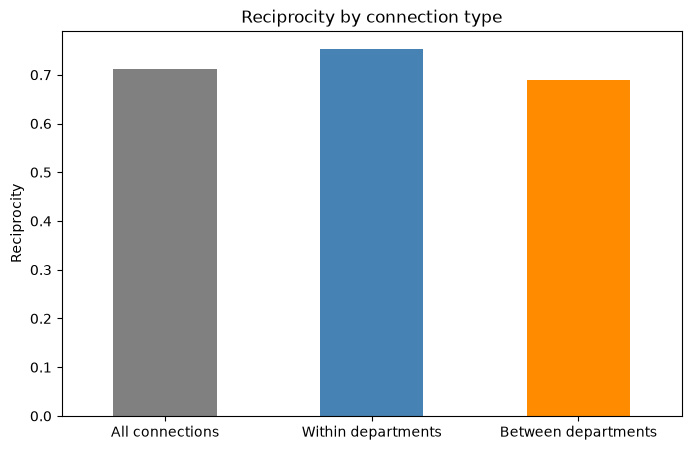

In [31]:
internal_graph = nx.DiGraph(
    (source, target) for source, target in graph.edges()
    if department_by_node[source] == department_by_node[target]
)
external_graph = nx.DiGraph(
    (source, target) for source, target in graph.edges()
    if department_by_node[source] != department_by_node[target]
)
reciprocity_summary = pd.Series(
    {
        "All connections": nx.reciprocity(graph),
        "Within departments": nx.reciprocity(internal_graph),
        "Between departments": nx.reciprocity(external_graph),
    },
    name="Reciprocity",
)

display(reciprocity_summary.to_frame())
reciprocity_summary.plot.bar(figsize=(8, 5), color=["gray", "steelblue", "darkorange"])
plt.ylabel("Reciprocity")
plt.title("Reciprocity by connection type")
plt.xticks(rotation=0)
plt.show()

### Results

- All connections: **0.711**.
- Within departments: **0.752**.
- Between departments: **0.689**.

### What this shows

This graph indicates that approximately 71.1% of all directed connections are also reciprocal. Most communication is therefore reciprocal rather than one-way broadcasting of information. Reciprocity of internal communication is slightly higher than that of interdepartmental communication, but both are very high. Note that reciprocity is not the same as path redundancy, so the higher reciprocity of interdepartmental communication does not necessarily mean that there are many bridge employees.

### Realistic explanation

The typical professional email exchange consists of a question, a document, a decision and a corresponding answer. Colleagues within the same department typically have more frequent interactions with each other than with colleagues from other departments. While external exchanges typically contain more information, formal requests, etc. than internal exchanges, they should not be described as mainly one-way communication.

Limitations

* Nodes are removed from the simulation on a permanent basis, while in real life, employees can be absent for a certain period of time.
* All communication links are treated equally because email counts are available. 
* Attack rankings were based on directed in-degree and out-degree, whereas the fragmentation was calculated on the undirected graph.
* The measure of bridge score for a node is highly correlated with its total degree; the external share and the number of departments reached are additional measures.
* It is possible that the concentration of top bridges in one department is influenced by the size of the department in addition to its position in the network.
* Losing external edges is not equivalent to losing the same proportion of email volume or organizational performance.
* Reciprocity is measured by the existence of links in both directions, not by the amount of emails sent and/or received.
* Random results will depend on the number of simulation samples, even though averaging over 20 trials will reduce the variation.
* An adaptive attack that calculates new rankings after each removal could be more destructive than the static attacks that were simulated.

Interpretation of structural importance

The robustness analysis can be interpreted as defining the importance of an employee’s communication role. The more people and departments an employee’s communication role is connected to, the more the role contributes to the continuity, stability and fluidity of communication within the university. This role is of high network value for the communication robustness, but not necessarily of high value to the university in other respects.

Short conclusion

Results

The results show that the network is very robust even to extreme attacks. Total-degree and out-degree based attacks cause the greatest amount of fragmentation in the network. The removal of nodes based on their bridge score results in the greatest amount of loss of interdepartmental links.

What this shows

The structural connectivity of the organization and the communication within the organization are not identical. Most of the remaining nodes are in the largest component. The cross-department connectivity, however, is mostly dependent on a small number of connectors. In the static simulations presented here, initiating many connections is more closely associated with structural cohesion than receiving many connections.

Realistic explanation

In addition to the university still being able to function within individual departments even after central contacts have been removed, the university’s services can still communicate with each other. However, the communication can be reduced or even made more difficult. Thus, the robustness of the communication role of a person within the university is not related to the personal or professional value of the person.

 ----
# Part E — Critical Reflection and Insights

## 1. Summary of the main findings

- The network is sparse but strongly clustered with short paths in the main connected component.
- Few communication roles with high degree or connecting different groups.
- Detected communities are related to but different from the **42 departments**.
- Most edges cross departments (**66.43%**).
- After removing 10% of nodes, the randomly attacked network contains **81.14%** of the cross-department edges, whereas the targeted attacked network contains **25.13–30.20%** of the cross-department edges.
- Communication between departments is affected more than the main network core which remains connected.

Communication is partially based on departmental structure but is also based on a small number of connectors.

## 2. Comparison with theoretical expectations

- **Erdős–Rényi:** The clustering coefficient of Erdős–Rényi graphs is around **0.032** whereas the empirical value for the network at hand is **0.399**.
- **Small-world properties:** The network under study is a small-world network with high clustering and short average path lengths. Its small-world ratio is **11.23**.
- **Barabási–Albert:** It can explain the presence of some of the highly connected nodes, as it produces hubs in the network.

None of the above models include the departments, the professional roles or the organizational constraints that shape the real world network of individuals’ communication choices.

## 3. Assumptions and limitations

- The data are **not timestamped** and do not have **email counts**. Edges are unweighted.
- Employees and departments are anonymous; hence we cannot even approximate the professional roles of the top nodes.
- Self-loops were removed from the graph. In some of the analyses we used an undirected version of the graph and applied the Louvain algorithm to this undirected projection.
- Approximations were used to calculate betweenness centrality (using a sample of nodes).
- In the targeted attacks, nodes are removed in a fixed order, i.e., the ranking is not recalculated after each node removal.
- The bridge score counts external neighbors only.
- No formal statistical test was applied to test for power-law degree distribution.

These choices should be considered when interpreting the results.

## 4. Sensitivity to analytical choices

Some results may change with the methods used:

- Random attacks were averaged over **20 trials** but results can still vary between trials.
- Louvain communities can vary with the random seed.
- Adaptive attacks may be more damaging than static attacks.
- Alternative bridge definitions may produce different rankings.
- Directed and undirected analyses may lead to different interpretations.
- Varying the percentage of nodes removed for the attacks can lead to different results.

The main conclusions can be reported based on the overall findings.

## 5. Real-world implications

The communication roles found in organizations can link up different departments. These internal connections are redundant enough to preserve a large connected core even when many links are removed. However, the links between departments are more vulnerable to removal in order to target certain departments.

The other links between departments can be increased, thereby decreasing the importance of the few connectors. However, the employees’ roles in the organization are not known, and the importance of a role for communication within an organization does not necessarily translate into the employee’s value for other organizational goals.

## 6. Possible improvements and future work

- Use timestamps to study how the network changes over time.
- Use email counts as edge weights and, where permitted, study the type or content of exchanges.
- Compare communities and departments using NMI or ARI.
- Apply a formal power-law test.
- Compare Louvain with Leiden or Infomap.
- Test adaptive attacks and alternative bridge definitions.
- Measure global efficiency in addition to the largest connected component.

## 7. Final conclusion

The email network is very sparse but strongly clustered with short average path lengths and communities largely reflecting organizational structure. Most links exist between departments. While the main connected component remains connected under attack, targeted removals cause a severe reduction in interdepartmental communication. Thus, the network is more dependent on a few connectors for communication between departments.